<a href="https://colab.research.google.com/github/leozeze/LRP1_heart/blob/main/02_notebooks/04_visium.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04. Visium 공간 분석: 누가 심근세포 곁에 있는가

README의 **분석 5**에 해당하고, 승인된 변경 **E**(대식세포와 지방세포를 이웃 후보에 추가)를 포함합니다.

Visium은 조직 절편 위의 지점(spot, 지름 55µm)마다 유전자 발현을 잰 데이터입니다. 지점 하나에 세포 여러 개가 섞여 있어서,
저자들이 cell2location이라는 방법으로 **각 지점에 어떤 세포 집단이 몇 개쯤 있는지**를 추정해 두었습니다. 이 추정량을 사용합니다.

- 같은 지점에 함께 있다 = 55µm 안에 이웃해 있다
- 인접 지점까지 넓히면 약 150µm 범위의 이웃

그림과 표는 드라이브의 `05_presentation` 폴더에 `04_`로 시작하는 이름으로 저장됩니다.

**주의**: 이 데이터에서는 세부 집단 이름이 조금 다릅니다. `FB4`는 단일세포 데이터의 `FB4_activated`, `vCM3`는 `vCM3_stressed`에 해당합니다.

## 1. 준비

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
PROJECT = Path('/content/drive/MyDrive/LRP1_heart')
VIS_DIR = PROJECT / '01_data' / 'visium'
VIS_DIR.mkdir(parents=True, exist_ok=True)
OUT = PROJECT / '05_presentation'
OUT.mkdir(parents=True, exist_ok=True)

RAW_DIR = Path('/content')                         # 원본을 받을 임시 위치
SPOTS_FILE = VIS_DIR / 'visium_spots_v1.parquet'   # 분석에 쓸 작은 표
if SPOTS_FILE.exists():
    print('이미 만든 표가 있습니다. 2~4번 셀은 건너뛰고 5번부터 실행해도 됩니다.')

Mounted at /content/drive


In [2]:
!pip -q install scanpy "pandas==2.2.3"
import re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import scanpy as sc
from scipy.spatial import cKDTree
from scipy.stats import wilcoxon

## 2. Visium 파일 받기

heartcellatlas.org → Data → **Visium — H5AD by region**에서 받을 부위의 **H5AD (LOG-NORMALISED)** 링크 주소를 복사해 아래에 붙여 넣습니다.

In [3]:
URLS = {
    'SP': 'https://cellgeni.cog.sanger.ac.uk/heartcellatlas/visium/visium-OCT_SP_lognormalised.h5ad',
    'LV': 'https://cellgeni.cog.sanger.ac.uk/heartcellatlas/visium/visium-OCT_LV_lognormalised.h5ad',
}

for key, url in URLS.items():
    path = RAW_DIR / f'visium_{key}.h5ad'
    !wget -c -q --show-progress -O "{path}" "{url}"
    print(f'{key}: {path.stat().st_size / 1e9:.2f} GB')

/content/visium_SP. 100%[===================>] 304.95M  44.0MB/s    in 7.7s    
SP: 0.32 GB
/content/visium_LV. 100%[===================>] 244.75M  42.4MB/s    in 6.2s    
LV: 0.26 GB


## 3. 파일 구조 확인

각 파일에 무엇이 들어 있는지, 특히 **세포 집단 추정량(cell2location 결과)**이 들어 있는지 확인합니다.

마지막 줄에 `cell2location 결과: 찾음`이 나오면 계속 진행하세요.
`없음`이 나오면 여기서 멈추고 이 셀의 출력을 보내주세요.

In [4]:
def find_abundance(a):
    """지점별 세포 집단 추정량 표를 찾아 (지점 x 집단) DataFrame으로 돌려줌"""
    keys = [k for k in ['q05_cell_abundance_w_sf', 'means_cell_abundance_w_sf'] if k in a.obsm]
    keys += [k for k in a.obsm.keys() if 'abundance' in k.lower() and k not in keys]
    for k in keys:
        m = a.obsm[k]
        if isinstance(m, pd.DataFrame):
            df = m.copy()
        else:
            try:
                names = list(a.uns['mod']['factor_names'])
            except Exception:
                continue
            df = pd.DataFrame(np.asarray(m), index=a.obs_names, columns=names)
        df.columns = [re.sub(r'^.*w_sf_', '', str(col)) for col in df.columns]
        return k, df
    cols = [col for col in a.obs.columns if re.match(r'^(FB\d|vCM\d|aCM\d)', str(col))]
    if cols:      # 추정량이 obs 열로 들어 있는 경우
        cols = [col for col in a.obs.columns if pd.api.types.is_float_dtype(a.obs[col]) and not re.search(r'counts|genes|frac|pct|score', col)]
        return 'obs', a.obs[cols].copy()
    return None, None

def slide_column(a):
    for col in ['sample', 'sangerID', 'library_id']:
        if col in a.obs:
            return col
    return None

found_all = True
for key in URLS:
    a = sc.read_h5ad(RAW_DIR / f'visium_{key}.h5ad')
    k, ab = find_abundance(a)
    scol = slide_column(a)
    print(f'===== {key} =====')
    print(f'지점 {a.n_obs:,}개,  유전자 {a.n_vars:,}개,  절편 {a.obs[scol].nunique() if scol else 1}개 (열: {scol})')
    print('obs 열:', list(a.obs.columns))
    print('obsm:', list(a.obsm.keys()), '| uns:', list(a.uns.keys()))
    print('유전자 이름 예:', list(a.var_names[:3]), '| var 열:', list(a.var.columns))
    print('X 최댓값:', float(a.X.max()))
    if ab is None:
        found_all = False
        print('추정량: 없음')
    else:
        print(f'추정량: obsm[{k!r}]에서 {ab.shape[1]}개 집단')
        print('집단 이름:', sorted(ab.columns))
    del a
print('\ncell2location 결과:', '찾음' if found_all else '없음')

===== SP =====
지점 8,643개,  유전자 33,538개,  절편 4개 (열: sangerID)
obs 열: ['array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'sangerID', 'region', 'donor', 'donor_type', 'age', 'gender', 'facility', 'modality', 'kit_10x', 'flushed', 'annotation_final', 'Adip1', 'Adip2', 'Adip3', 'B', 'B_plasma', 'CD14+Mo', 'CD16+Mo', 'CD4+T_act', 'CD4+T_naive', 'CD8+T_cytox', 'CD8+T_em', 'CD8+T_te', 'CD8+T_trans', 'DC', 'EC10_CMC-like', 'EC1_cap', 'EC2_cap', 'EC3_cap', 'EC4_immune', 'EC5_art', 'EC6_ven', 'EC7_endocardial', 'EC8_ln', 'FB1', 'FB2', 'FB3', 'FB4_activated', 'FB5', 'FB6', 'ILC', 'LYVE1+IGF1+MP', 'LYVE1+MP_cycling', 'LYVE1+TIMD4+MP', 'MAIT-like', 'Mast', 'Meso', 'MoMP', 'NC1_glial', 'NC2_glial_NGF+', 'NK_CD16hi', 'NK_CD56hi', 'Neut', 'PC1_vent', 'PC2_atria', 'PC3_str', 'SAN_P_cell', 'SMC1_basic', 'SMC2_art', 'T/NK_cycling', 'aCM1', 'aCM2', 'aCM3', 'aCM4', 'AVN_bundle_cell', 'PC4_CMC-like', 'vCM1', 'vCM2', 'vCM3_stressed', 'vCM4', 'vCM5'

## 4. 분석용 표 만들기

파일마다 필요한 것만 뽑아 **지점 하나가 한 줄인 표**로 합칩니다.

- 위치: 절편 이름, 좌표
- 유전자 발현(`gene__` 로 시작하는 열): LRP1, sheddase, 그리고 조직 구조를 확인할 유전자 몇 개
- 세포 집단 추정량(`ab__` 로 시작하는 열)

조직 구조 확인용 유전자는 2020년 논문의 세포 유형 표지(TTN, DCN, C1QA, CD68, ADIPOQ)와
2023년 논문 저자들이 스트레스 니치를 그릴 때 쓴 유전자(NPPB, COL1A1, COL3A1)입니다.

In [8]:
TARGET = ['LRP1']
SHEDDASES = ['ADAM10', 'ADAM12', 'ADAM17', 'MMP14', 'MMP15', 'MMP16', 'MMP17', 'BACE1']
CONTEXT = ['TTN', 'DCN', 'C1QA', 'CD68', 'ADIPOQ', 'NPPB', 'COL1A1', 'COL3A1']

def build_spot_table(key):
    a = sc.read_h5ad(RAW_DIR / f'visium_{key}.h5ad')
    symbols = pd.Index(a.var_names.astype(str))
    if 'LRP1' not in symbols:
        for col in a.var.columns:
            if 'LRP1' in set(a.var[col].astype(str)):
                symbols = pd.Index(a.var[col].astype(str))
                break
    genes = [g for g in TARGET + SHEDDASES + CONTEXT if g in symbols]
    idx = [int(np.flatnonzero(symbols == g)[0]) for g in genes]
    X = a.X[:, idx]
    X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
    if float(a.X.max()) > 30:       # 원시 개수로 보이면 정규화
        total = np.asarray(a.X.sum(axis=1)).ravel()
        X = np.log1p(X / total[:, None] * 1e4)
        print(f'{key}: 원시 개수로 보여 로그 정규화를 적용했습니다')

    scol = slide_column(a)
    t = pd.DataFrame(index=a.obs_names)
    t['file'] = key
    t['slide'] = a.obs[scol].astype(str).values if scol else key
    for col in ['region', 'donor', 'array_row', 'array_col', 'annotation_final']:
        if col in a.obs:
            t[col] = a.obs[col].values
    xy = np.asarray(a.obsm['spatial'])
    t['x'], t['y'] = xy[:, 0], xy[:, 1]
    t = t.join(pd.DataFrame(X, index=a.obs_names, columns=[f'gene__{g}' for g in genes]))
    _, ab = find_abundance(a)
    t = t.join(ab.add_prefix('ab__').astype('float32'))
    return t.reset_index(names='spot')

spots = pd.concat([build_spot_table(k) for k in URLS], ignore_index=True)
spots.columns = [str(col) for col in spots.columns]
spots.to_parquet(SPOTS_FILE)
print(f'저장 완료: {SPOTS_FILE}  ({SPOTS_FILE.stat().st_size / 1e6:.1f} MB),  지점 {len(spots):,}개')

저장 완료: /content/drive/MyDrive/LRP1_heart/01_data/visium/visium_spots_v1.parquet  (7.2 MB),  지점 18,269개


## 5. 표 불러오기와 세포 집단 묶기

여기서부터는 드라이브의 작은 표만 사용합니다.

In [9]:
spots = pd.read_parquet(SPOTS_FILE)
spots = spots.rename(columns={'ab__FB4_activated': 'ab__FB4', 'ab__vCM3_stressed': 'ab__vCM3'})
STATES = [col[4:] for col in spots.columns if col.startswith('ab__')]
GENES = [col[6:] for col in spots.columns if col.startswith('gene__')]
SHED = [g for g in ['ADAM10', 'ADAM12', 'ADAM17', 'MMP14', 'MMP15', 'MMP16', 'MMP17', 'BACE1'] if g in GENES]

GROUPS = {
    'Fibroblast': [s for s in STATES if re.match(r'^FB\d', s)],
    'Ventricular CM': [s for s in STATES if re.match(r'^vCM\d', s)],
    'Atrial CM': [s for s in STATES if re.match(r'^aCM\d', s)],
    'Myeloid': [s for s in STATES if re.search(r'MP|Mo$|^DC$|^Mast$|^Neut$', s)],
    'Adipocyte': [s for s in STATES if re.match(r'^Adip', s)],
    'Endothelial': [s for s in STATES if re.match(r'^EC\d', s)],
    'Mural': [s for s in STATES if re.match(r'^(PC|SMC)\d', s)],
}
used = {s for v in GROUPS.values() for s in v}
GROUPS['Other'] = [s for s in STATES if s not in used]
for g, v in GROUPS.items():
    spots[f'grp__{g}'] = spots[[f'ab__{s}' for s in v]].sum(axis=1) if v else 0.0
    print(f'{g} ({len(v)}): {v}')

SENDERS = GROUPS['Fibroblast'] + GROUPS['Myeloid'] + GROUPS['Adipocyte']   # 심근세포의 이웃 후보
SENDER_GROUP = {s: g for g in ['Fibroblast', 'Myeloid', 'Adipocyte'] for s in GROUPS[g]}
GROUP_COLOR = {'Fibroblast': '#d9534f', 'Myeloid': '#4a90d9', 'Adipocyte': '#e6a817'}

slides = spots.groupby(['file', 'slide']).size().rename('n_spots').reset_index()
slides.to_csv(OUT / '04_slides.csv', index=False)
print(f'\n절편 {len(slides)}개')
slides

Fibroblast (6): ['FB1', 'FB2', 'FB3', 'FB4', 'FB5', 'FB6']
Ventricular CM (5): ['vCM1', 'vCM2', 'vCM3', 'vCM4', 'vCM5']
Atrial CM (5): ['aCM1', 'aCM2', 'aCM3', 'aCM4', 'aCM5']
Myeloid (9): ['CD14+Mo', 'CD16+Mo', 'DC', 'LYVE1+IGF1+MP', 'LYVE1+MP_cycling', 'LYVE1+TIMD4+MP', 'Mast', 'MoMP', 'Neut']
Adipocyte (4): ['Adip1', 'Adip2', 'Adip3', 'Adip4']
Endothelial (10): ['EC10_CMC-like', 'EC1_cap', 'EC2_cap', 'EC3_cap', 'EC4_immune', 'EC5_art', 'EC6_ven', 'EC7_endocardial', 'EC8_ln', 'EC9_FB-like']
Mural (6): ['PC1_vent', 'PC2_atria', 'PC3_str', 'SMC1_basic', 'SMC2_art', 'PC4_CMC-like']
Other (27): ['B', 'B_plasma', 'CD4+T_act', 'CD4+T_naive', 'CD8+T_cytox', 'CD8+T_em', 'CD8+T_te', 'CD8+T_trans', 'ILC', 'MAIT-like', 'Meso', 'NC1_glial', 'NC2_glial_NGF+', 'NK_CD16hi', 'NK_CD56hi', 'SAN_P_cell', 'T/NK_cycling', 'AVN_bundle_cell', 'AVN_P_cell', 'CD4+T_Tfh', 'CD4+T_Th1', 'CD4+T_Th2', 'CD4+T_reg', 'NC5_glial', 'NC3_glial', 'NC6_schwann', 'gdT']

절편 9개


,file,slide,n_spots
0,LV,HCAHeartST8795933,2891
1,LV,HCAHeartST9383352,2260
2,LV,HCAHeartST9383354,2073
3,LV,HCAHeartST9383356,1166
4,LV,HCAHeartST9383358,1236
5,SP,HCAHeartST10550732,2199
6,SP,HCAHeartST11350375,2843
7,SP,HCAHeartST8795938,1564
8,SP,HCAHeartST8795939,2037


## 6. 조직 지도

대표 절편 하나에서 유전자 발현과 세포 집단 추정량을 조직 위치대로 그립니다.
저자들이 스트레스 니치를 정의한 심실중격 절편(`HCAHeartST8795938`)이 있으면 그것을, 없으면 vCM3와 FB4가 가장 많이 겹치는 절편을 고릅니다.

대표 절편: HCAHeartST8795938


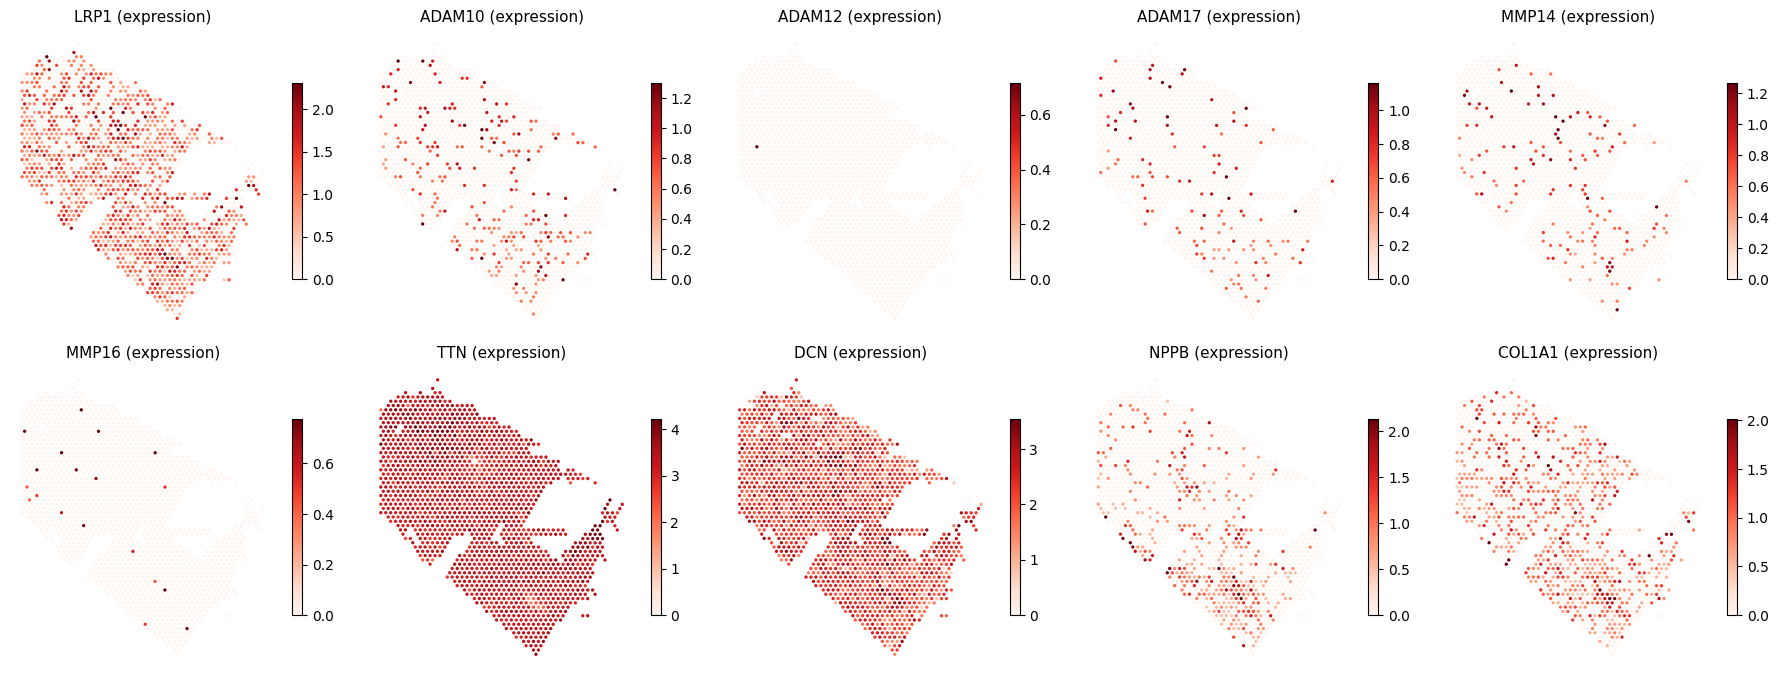

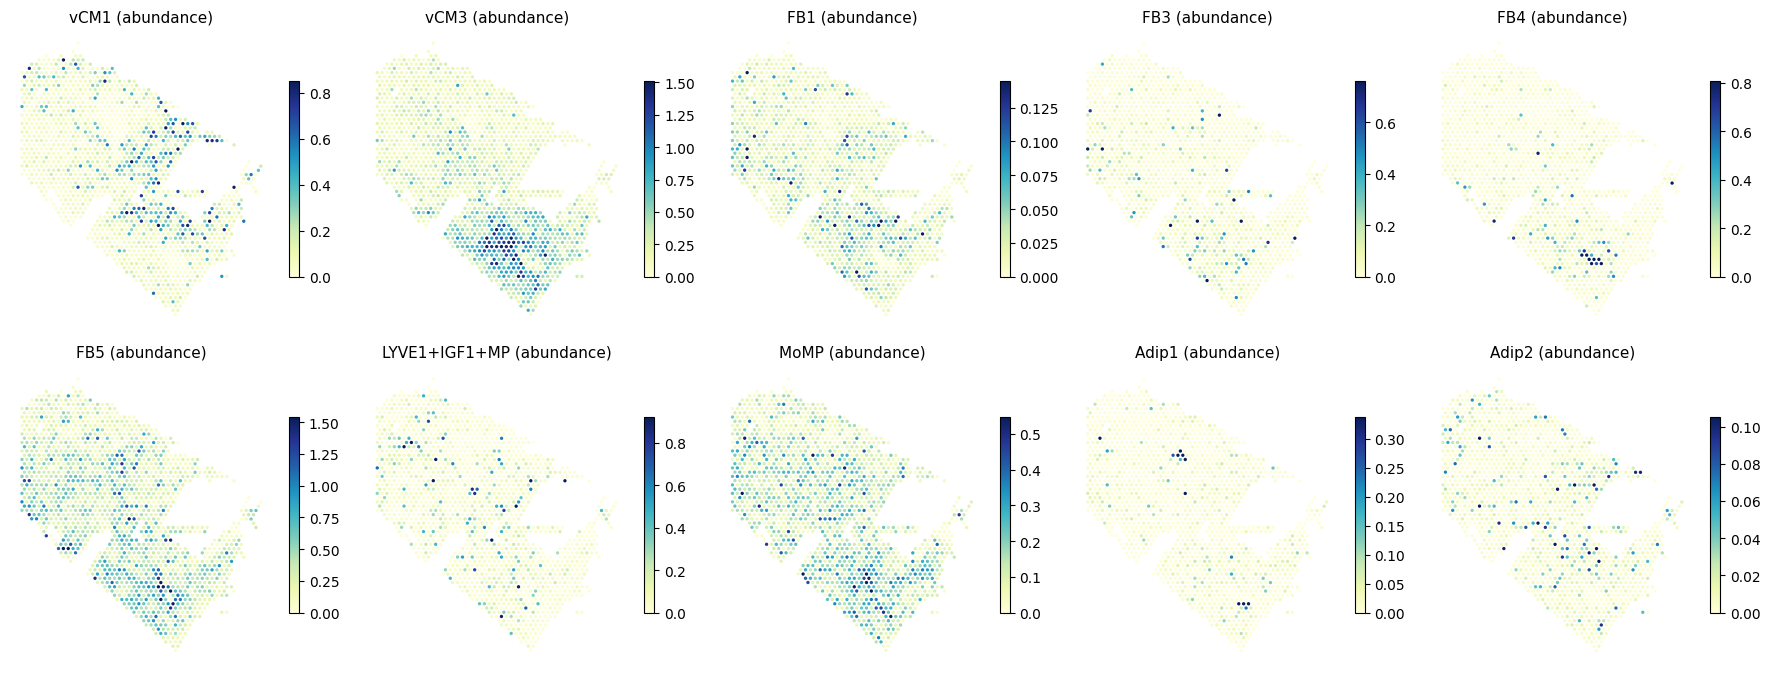

In [10]:
def has(*states):
    return all(f'ab__{s}' in spots.columns for s in states)

if has('vCM3', 'FB4'):
    spots['niche_score'] = spots['ab__vCM3'] * spots['ab__FB4']
if 'HCAHeartST8795938' in set(spots['slide']):
    REP = 'HCAHeartST8795938'
elif 'niche_score' in spots:
    REP = spots.groupby('slide')['niche_score'].mean().idxmax()
else:
    REP = slides['slide'].iloc[0]
print('대표 절편:', REP)

def tissue_maps(slide, columns, titles, fname, cmap='Reds', ncol=5):
    d = spots[spots['slide'] == slide]
    nrow = int(np.ceil(len(columns) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.5 * nrow), squeeze=False)
    size = max(2, 9000 / len(d))
    for ax, col, title in zip(axes.ravel(), columns, titles):
        v = d[col].values
        vmax = np.percentile(v, 99.5) or v.max() or 1
        sca = ax.scatter(d['x'], d['y'], c=v, s=size, cmap=cmap, vmin=0, vmax=vmax, linewidths=0)
        ax.invert_yaxis()
        ax.set_aspect('equal')
        ax.axis('off')
        ax.set_title(title, fontsize=11)
        plt.colorbar(sca, ax=ax, shrink=0.6)
    for ax in axes.ravel()[len(columns):]:
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(OUT / fname, dpi=200, bbox_inches='tight')
    plt.show()

gene_panels = [g for g in ['LRP1', 'ADAM10', 'ADAM12', 'ADAM17', 'MMP14', 'MMP16', 'TTN', 'DCN', 'NPPB', 'COL1A1'] if g in GENES]
tissue_maps(REP, [f'gene__{g}' for g in gene_panels], [f'{g} (expression)' for g in gene_panels], '04_map_genes.png')

state_panels = [s for s in ['vCM1', 'vCM3', 'FB1', 'FB3', 'FB4', 'FB5', 'LYVE1+IGF1+MP', 'MoMP', 'Adip1', 'Adip2'] if has(s)]
tissue_maps(REP, [f'ab__{s}' for s in state_panels], [f'{s} (abundance)' for s in state_panels], '04_map_states.png', cmap='YlGnBu')

## 7. 분석 5: 어떤 세포가 심근세포 곁에 있는가

이웃 후보(섬유모세포, 골수계, 지방세포의 각 집단)가 많은 지점에 심근세포 집단도 많은지를 절편마다 상관계수(Spearman)로 계산하고, 절편들의 중앙값을 냅니다.

- 값이 **양수**면 같은 자리에 함께 있는 경향, **음수**면 서로 다른 자리에 있는 경향입니다.
- **same spot**: 같은 지점 안(55µm). **with neighbours**: 인접 지점까지 포함한 범위에서 심근세포 양을 평균한 것.
- 그 절편에 거의 없는 집단(평균 추정량 0.02 미만)은 그 절편 계산에서 뺍니다.

해석할 때 주의: 한 지점에 들어갈 수 있는 세포 수가 정해져 있어서, 지점을 가득 채우는 심근세포(특히 가장 흔한 vCM1)와는 다른 세포들이 대체로 음의 상관을 보입니다. 그래서 **절대값보다 후보들 사이의 상대적 순서**를 보세요.

절편 9개에서 계산


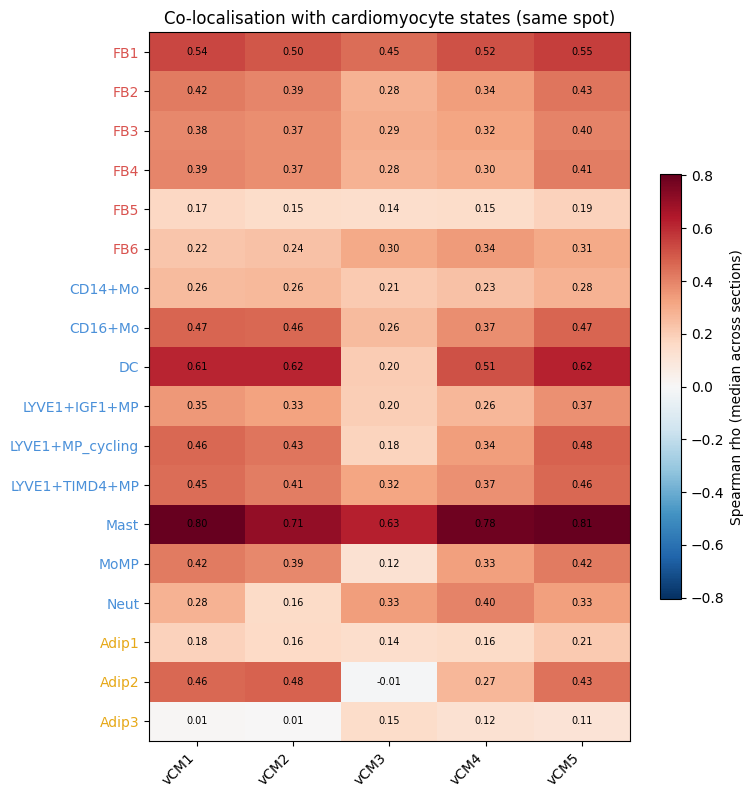

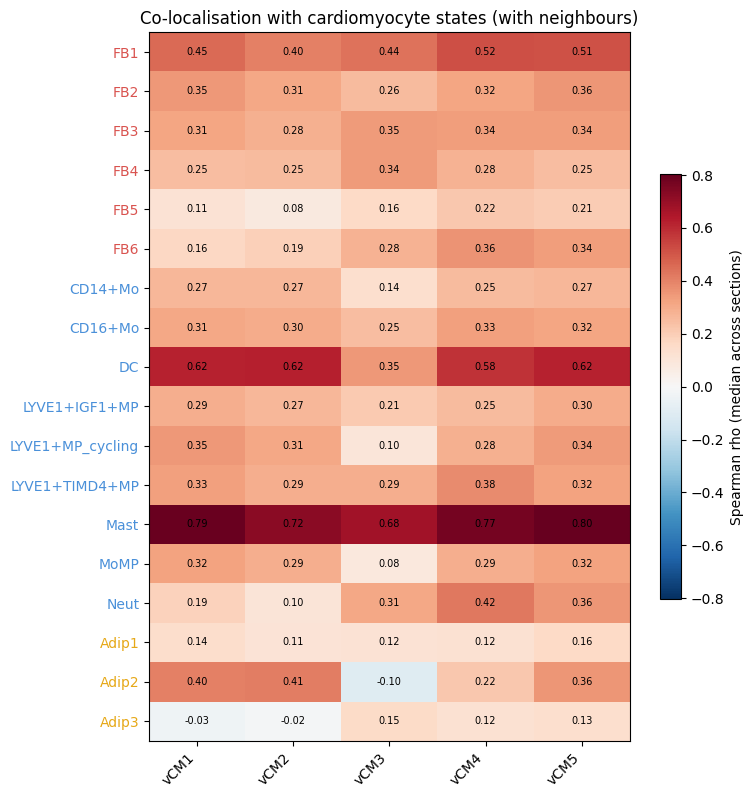

In [11]:
def neighbour_mean(d, cols):
    """각 지점과 인접 지점(가장 가까운 지점 간 거리의 1.3배 이내)의 평균"""
    xy = d[['x', 'y']].values
    tree = cKDTree(xy)
    nn = tree.query(xy, k=2)[0][:, 1]
    pairs = tree.query_ball_point(xy, r=np.median(nn) * 1.3)
    vals = d[cols].values
    return pd.DataFrame(np.vstack([vals[p].mean(axis=0) for p in pairs]), index=d.index, columns=cols)

MIN_ABUND = 0.02
CM_STATES = GROUPS['Ventricular CM'] + GROUPS['Atrial CM']
rows = []
for (f, s), d in spots.groupby(['file', 'slide']):
    send = [x for x in SENDERS if d[f'ab__{x}'].mean() >= MIN_ABUND]
    recv = [x for x in CM_STATES if d[f'ab__{x}'].mean() >= MIN_ABUND]
    if not send or not recv:
        continue
    A = d[[f'ab__{x}' for x in send]].rank()
    B_same = d[[f'ab__{x}' for x in recv]].rank()
    B_nb = neighbour_mean(d, [f'ab__{x}' for x in recv]).rank()
    for x in send:
        for y in recv:
            rows.append(dict(file=f, slide=s, sender=x, group=SENDER_GROUP[x], cm_state=y,
                             rho_same=A[f'ab__{x}'].corr(B_same[f'ab__{y}']),
                             rho_neighbour=A[f'ab__{x}'].corr(B_nb[f'ab__{y}'])))
coloc = pd.DataFrame(rows)
coloc.round(4).to_csv(OUT / '04_colocalisation_per_slide.csv', index=False)
print(f'절편 {coloc["slide"].nunique()}개에서 계산')

def coloc_heatmap(value, title, fname):
    m = coloc.pivot_table(index='sender', columns='cm_state', values=value, aggfunc='median')
    m = m.reindex([s for s in SENDERS if s in m.index])
    m.round(3).to_csv(OUT / fname.replace('.png', '.csv'))
    fig, ax = plt.subplots(figsize=(0.9 * m.shape[1] + 3.2, 0.36 * m.shape[0] + 1.6))
    lim = max(0.2, np.nanmax(np.abs(m.values)))
    im = ax.imshow(m.values, cmap='RdBu_r', norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim), aspect='auto')
    ax.set_xticks(range(m.shape[1]))
    ax.set_xticklabels(m.columns, rotation=45, ha='right')
    ax.set_yticks(range(m.shape[0]))
    ax.set_yticklabels(m.index)
    for lab in ax.get_yticklabels():
        lab.set_color(GROUP_COLOR[SENDER_GROUP[lab.get_text()]])
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            if not np.isnan(m.values[i, j]):
                ax.text(j, i, f'{m.values[i, j]:.2f}', ha='center', va='center', fontsize=7)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, shrink=0.6, label='Spearman rho (median across sections)')
    plt.tight_layout()
    plt.savefig(OUT / fname, dpi=200, bbox_inches='tight')
    plt.show()
    return m

m_same = coloc_heatmap('rho_same', 'Co-localisation with cardiomyocyte states (same spot)', '04_heatmap_coloc_same_spot.png')
m_nb = coloc_heatmap('rho_neighbour', 'Co-localisation with cardiomyocyte states (with neighbours)', '04_heatmap_coloc_neighbours.png')

### 스트레스 심근세포(vCM3) 곁에는 누가 있는가

이웃 후보를 vCM3와의 상관이 높은 순으로 줄 세웁니다. 점 하나가 절편 하나이고, 색은 세포 유형입니다(빨강 섬유모세포, 파랑 골수계, 노랑 지방세포).

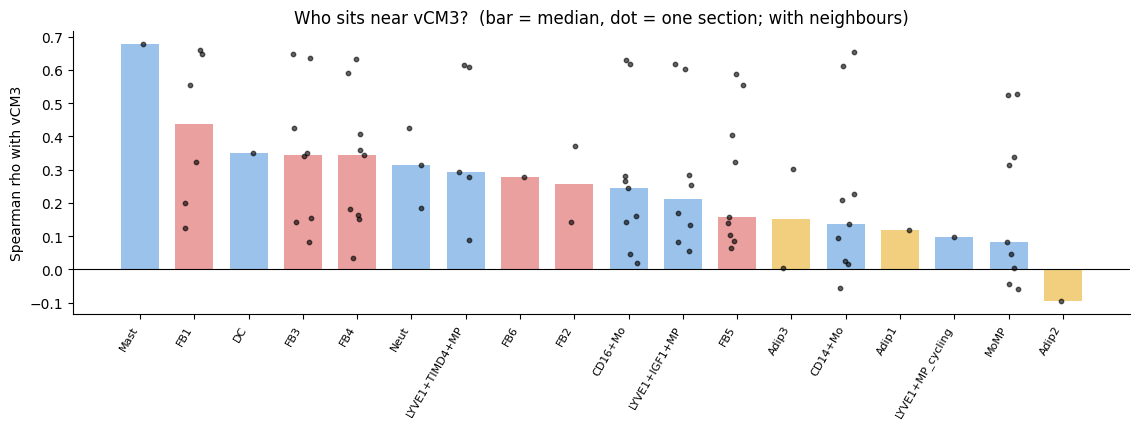

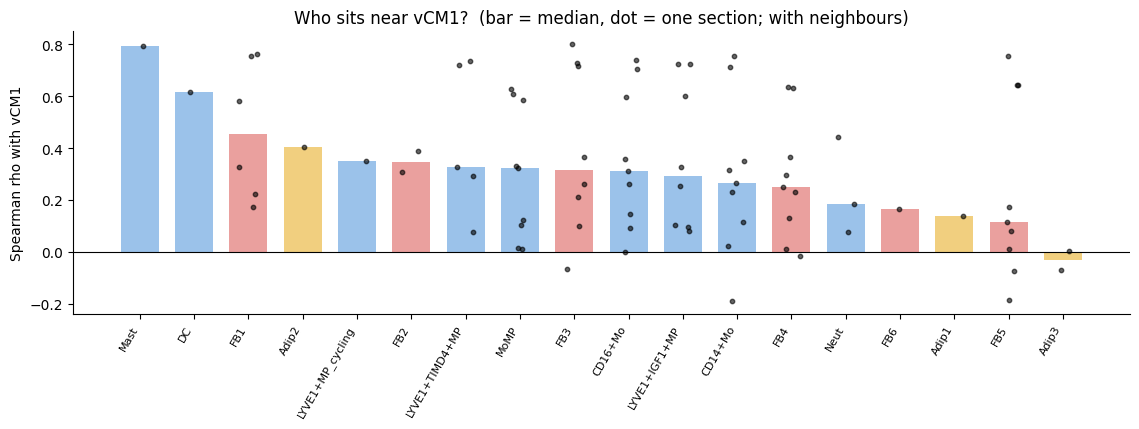

In [12]:
def rank_plot(cm_state, value='rho_neighbour'):
    d = coloc[coloc['cm_state'] == cm_state]
    if d.empty:
        print(cm_state, '추정량이 없어 건너뜁니다')
        return
    order = d.groupby('sender')[value].median().sort_values(ascending=False).index
    fig, ax = plt.subplots(figsize=(0.5 * len(order) + 2.5, 4.4))
    rng = np.random.default_rng(0)
    for i, s in enumerate(order):
        v = d.loc[d['sender'] == s, value].values
        col = GROUP_COLOR[SENDER_GROUP[s]]
        ax.bar(i, np.median(v), color=col, alpha=0.55, width=0.7)
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=10, color='black', alpha=0.6, zorder=3)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=60, ha='right', fontsize=8)
    ax.set_ylabel('Spearman rho with ' + cm_state)
    ax.set_title(f'Who sits near {cm_state}?  (bar = median, dot = one section; with neighbours)')
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.savefig(OUT / f'04_rank_near_{cm_state}.png', dpi=200, bbox_inches='tight')
    plt.show()

for cm in ['vCM3', 'vCM1']:
    rank_plot(cm)

## 8. 스트레스 니치 안에서 LRP1과 sheddase

저자들의 방법을 따라 **vCM3 추정량 x FB4 추정량이 0.03보다 큰 지점**을 스트레스 니치로 잡습니다
(저자들은 여기에 "5개 이상 붙어 있을 것"이라는 조건을 더했는데, 여기서는 생략했습니다).

니치 지점과 비교하는 대상은 두 가지입니다.
- **rest**: 같은 절편의 나머지 모든 지점
- **FB-rich rest**: 나머지 지점 중 섬유모세포가 많은 상위 25%. 니치에는 정의상 섬유모세포가 많으므로, "그냥 섬유모세포가 많아서" 생기는 차이를 걸러내기 위한 비교입니다.

표의 `niche_higher / n_slides`는 니치 쪽이 더 높았던 절편 수입니다. 니치 지점이 20개 미만인 절편은 제외합니다.

니치가 충분히 있는 절편: 9개


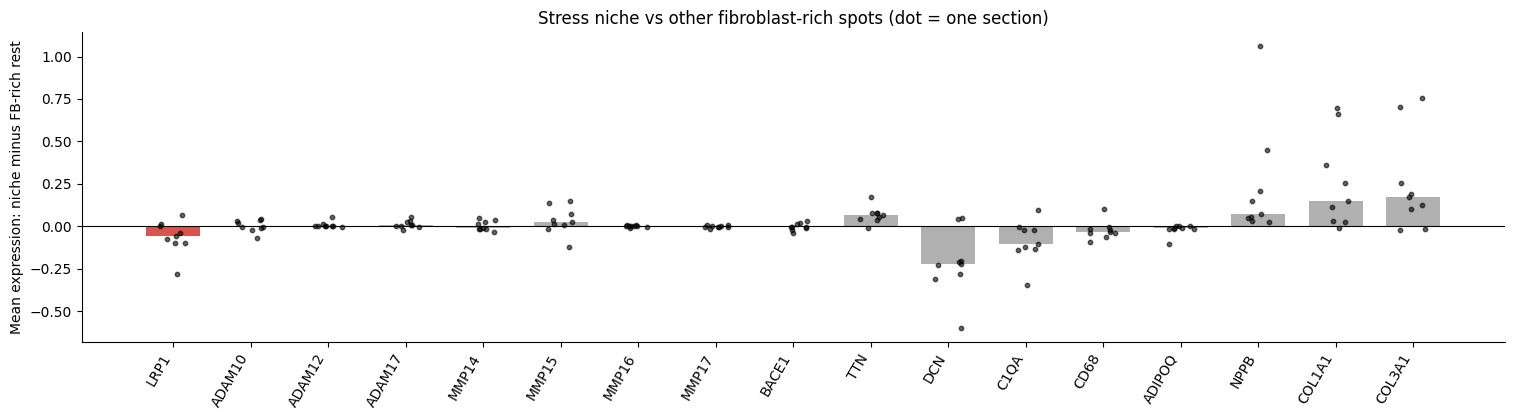

,measure,kind,n_slides,niche_mean,rest_mean,fb_rich_rest_mean,niche_higher_vs_rest,p_vs_rest,niche_higher_vs_fb_rich_rest,p_vs_fb_rich_rest
0,LRP1,gene,9,0.639,0.476,0.737,9,0.004,3,0.098
1,ADAM10,gene,9,0.133,0.109,0.126,6,0.203,4,0.734
2,ADAM12,gene,9,0.000,0.001,0.000,4,0.375,4,0.188
3,ADAM17,gene,9,0.060,0.047,0.056,8,0.012,6,0.129
4,MMP14,gene,9,0.094,0.063,0.105,9,0.004,4,0.652
5,MMP15,gene,9,0.208,0.155,0.161,8,0.027,7,0.164
6,MMP16,gene,9,0.006,0.004,0.006,5,0.219,4,0.844
7,MMP17,gene,9,0.006,0.005,0.002,4,0.820,4,1.000
8,BACE1,gene,9,0.047,0.049,0.052,7,0.055,3,0.820
9,TTN,gene,9,3.154,3.221,3.116,5,1.000,8,0.008


In [13]:
NICHE_THRESH, MIN_NICHE = 0.03, 20
if 'niche_score' not in spots:
    print('vCM3 또는 FB4 추정량이 없어 이 절을 건너뜁니다')
    niche_test = pd.DataFrame()
else:
    spots['niche'] = spots['niche_score'] > NICHE_THRESH
    measure = [f'gene__{g}' for g in GENES] + [f'grp__{g}' for g in ['Myeloid', 'Adipocyte', 'Fibroblast']]
    rows = []
    for (f, s), d in spots.groupby(['file', 'slide']):
        n_in = int(d['niche'].sum())
        if n_in < MIN_NICHE or n_in > len(d) - MIN_NICHE:
            continue
        rest = d[~d['niche']]
        fb_rich = rest[rest['grp__Fibroblast'] >= rest['grp__Fibroblast'].quantile(0.75)]
        for m in measure:
            rows.append(dict(file=f, slide=s, measure=m.split('__')[1], kind=m.split('__')[0], n_niche=n_in,
                             niche=d.loc[d['niche'], m].mean(), rest=rest[m].mean(), fb_rich_rest=fb_rich[m].mean()))
    per_slide = pd.DataFrame(rows)
    per_slide.round(4).to_csv(OUT / '04_niche_per_slide.csv', index=False)
    print(f'니치가 충분히 있는 절편: {per_slide["slide"].nunique()}개')

    out = []
    for m, d in per_slide.groupby('measure', sort=False):
        row = dict(measure=m, kind=d['kind'].iloc[0], n_slides=len(d),
                   niche_mean=d['niche'].median(), rest_mean=d['rest'].median(), fb_rich_rest_mean=d['fb_rich_rest'].median())
        for comp in ['rest', 'fb_rich_rest']:
            diff = d['niche'] - d[comp]
            row[f'niche_higher_vs_{comp}'] = int((diff > 0).sum())
            row[f'p_vs_{comp}'] = wilcoxon(diff).pvalue if len(d) >= 6 and (diff != 0).any() else np.nan
        out.append(row)
    niche_test = pd.DataFrame(out)
    niche_test.round(4).to_csv(OUT / '04_niche_test.csv', index=False)

    fig, ax = plt.subplots(figsize=(0.75 * len(GENES) + 2.5, 4.3))
    rng = np.random.default_rng(0)
    for i, g in enumerate(GENES):
        d = per_slide[per_slide['measure'] == g]
        v = (d['niche'] - d['fb_rich_rest']).values
        ax.bar(i, np.median(v) if len(v) else 0, color='#d9534f' if g == 'LRP1' else '#b0b0b0', width=0.7)
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=10, color='black', alpha=0.6, zorder=3)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_xticks(range(len(GENES)))
    ax.set_xticklabels(GENES, rotation=60, ha='right')
    ax.set_ylabel('Mean expression: niche minus FB-rich rest')
    ax.set_title('Stress niche vs other fibroblast-rich spots (dot = one section)')
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    plt.savefig(OUT / '04_niche_vs_fbrich.png', dpi=200, bbox_inches='tight')
    plt.show()
niche_test.round(3)

니치 위치를 대표 절편에서 확인합니다.

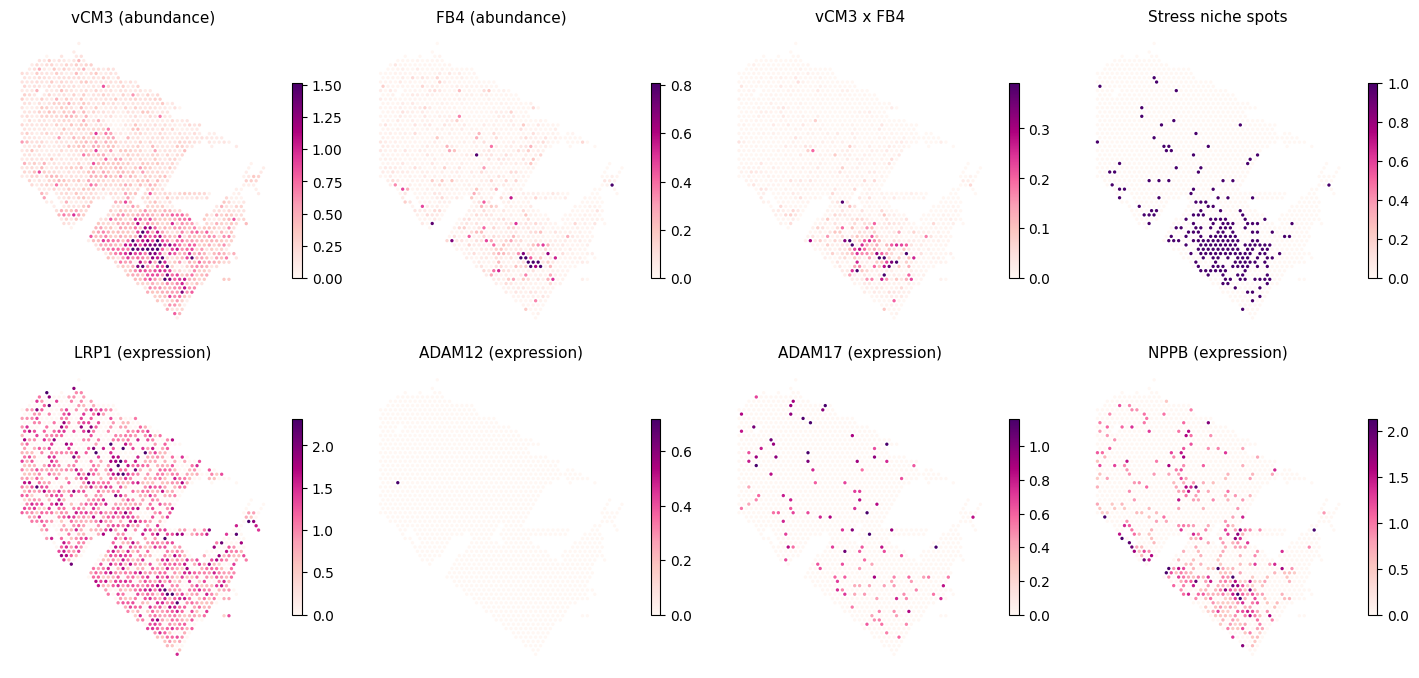

In [14]:
if 'niche' in spots:
    spots['niche_num'] = spots['niche'].astype(float)
    cols = ['ab__vCM3', 'ab__FB4', 'niche_score', 'niche_num'] + [f'gene__{g}' for g in ['LRP1', 'ADAM12', 'ADAM17', 'NPPB'] if g in GENES]
    titles = ['vCM3 (abundance)', 'FB4 (abundance)', 'vCM3 x FB4', 'Stress niche spots'] + [f'{g} (expression)' for g in ['LRP1', 'ADAM12', 'ADAM17', 'NPPB'] if g in GENES]
    tissue_maps(REP, cols, titles, '04_map_stress_niche.png', cmap='RdPu', ncol=4)

## 9. 조직에서 LRP1 신호는 어느 세포가 있는 곳에서 나오는가

지점의 유전자 발현량과 세포 유형별 추정량 합계 사이의 상관(절편별 Spearman의 중앙값)입니다.
예를 들어 LRP1 줄에서 Fibroblast 칸이 가장 높으면, 조직에서 LRP1 신호가 섬유모세포가 많은 자리와 가장 잘 겹친다는 뜻입니다.
승인된 추가 분석 B(세포 수를 반영한 LRP1 공급 비중)의 공간 쪽 근거로도 쓸 수 있습니다.

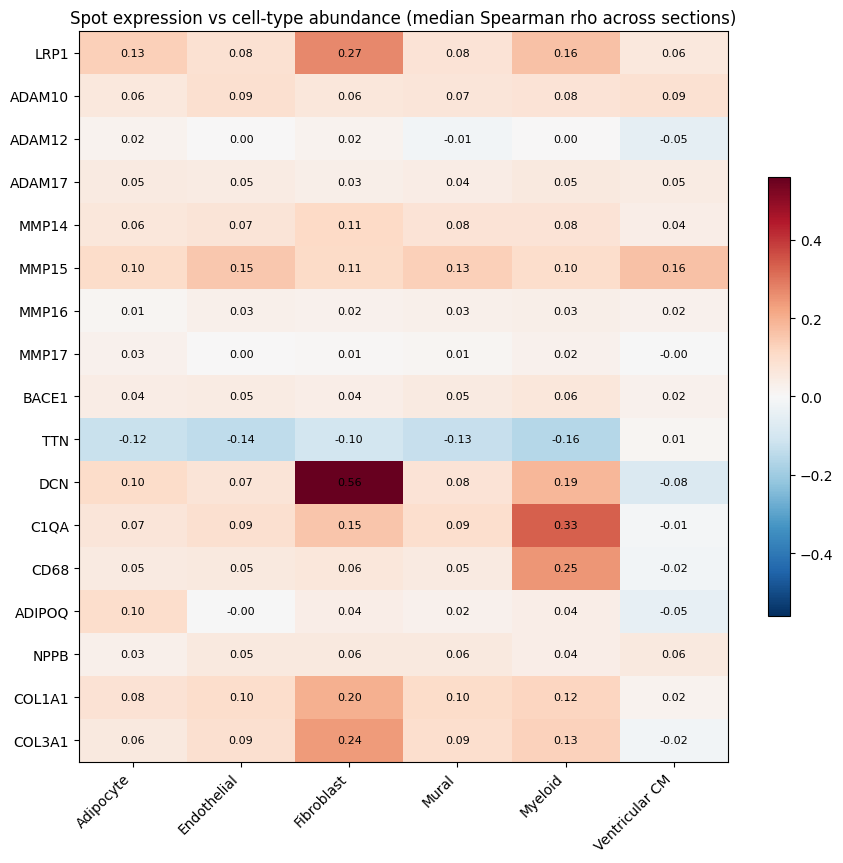

In [15]:
group_cols = [f'grp__{g}' for g in GROUPS if g != 'Other']
rows = []
for (f, s), d in spots.groupby(['file', 'slide']):
    R = d[[f'gene__{g}' for g in GENES] + group_cols].rank()
    for g in GENES:
        if d[f'gene__{g}'].nunique() < 3:
            continue
        for gc in group_cols:
            if d[gc].mean() < MIN_ABUND:
                continue
            rows.append(dict(file=f, slide=s, gene=g, group=gc[5:], rho=R[f'gene__{g}'].corr(R[gc])))
gene_group = pd.DataFrame(rows)
gene_group.round(4).to_csv(OUT / '04_gene_vs_celltype_per_slide.csv', index=False)

m = gene_group.pivot_table(index='gene', columns='group', values='rho', aggfunc='median').reindex(GENES)
m.round(3).to_csv(OUT / '04_gene_vs_celltype.csv')
fig, ax = plt.subplots(figsize=(1.1 * m.shape[1] + 2.5, 0.42 * m.shape[0] + 1.6))
lim = max(0.2, np.nanmax(np.abs(m.values)))
im = ax.imshow(m.values, cmap='RdBu_r', norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim), aspect='auto')
ax.set_xticks(range(m.shape[1]))
ax.set_xticklabels(m.columns, rotation=45, ha='right')
ax.set_yticks(range(m.shape[0]))
ax.set_yticklabels(m.index)
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        if not np.isnan(m.values[i, j]):
            ax.text(j, i, f'{m.values[i, j]:.2f}', ha='center', va='center', fontsize=8)
ax.set_title('Spot expression vs cell-type abundance (median Spearman rho across sections)')
plt.colorbar(im, ax=ax, shrink=0.6)
plt.tight_layout()
plt.savefig(OUT / '04_heatmap_gene_vs_celltype.png', dpi=200, bbox_inches='tight')
plt.show()

In [16]:
for f in sorted(OUT.glob('04_*')):
    print(f.name)

04_colocalisation_per_slide.csv
04_gene_vs_celltype.csv
04_gene_vs_celltype_per_slide.csv
04_heatmap_coloc_neighbours.csv
04_heatmap_coloc_neighbours.png
04_heatmap_coloc_same_spot.csv
04_heatmap_coloc_same_spot.png
04_heatmap_gene_vs_celltype.png
04_map_genes.png
04_map_states.png
04_map_stress_niche.png
04_niche_per_slide.csv
04_niche_test.csv
04_niche_vs_fbrich.png
04_rank_near_vCM1.png
04_rank_near_vCM3.png
04_slides.csv
